# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
warnings.filterwarnings('ignore')

# Reading of 1183 Data

Loading 1183 data

In [2]:
df=pd.read_csv("C:\\Users\\Devesh\\Downloads\\1183_Final_Dataset.csv")

In [3]:
df.head()

,Unnamed: 0,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR,PFSCR,AEPT,AECONT,Severity_1.0,Severity_2.0,Severity_3.0,Severity_4.0
0,0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
1,1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
2,2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
3,3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,-11.0,N,54.0,1.0,Dermatitis acneiform,N,2,0,0,0
4,4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,Y,54.0,1.0,Dermatitis acneiform,N,2,0,0,0


In [4]:
df= df.drop(columns=['Unnamed: 0','AEPT', 'AECONT', 'Severity_1.0', 'Severity_2.0','Severity_3.0', 'Severity_4.0'])

In [5]:
df.shape

(7100293, 15)

In [6]:
df.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR,PFSCR
0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,-11.0,N,54.0,1.0
1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,Y,54.0,1.0
2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,N,54.0,1.0
3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,-11.0,N,54.0,1.0
4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,Y,54.0,1.0


In [7]:
df = df.drop_duplicates(keep='first')

In [8]:
def find_min_max_lssld_excl_zero(subjid_group):
    non_zero_lssld = subjid_group[subjid_group['LSSLD'] != 0]
    if not non_zero_lssld.empty:
        min_visitdy_y = non_zero_lssld['VISITDY_y'].min()
        max_visitdy_y = non_zero_lssld['VISITDY_y'].max()
        min_lssld = non_zero_lssld.loc[non_zero_lssld['VISITDY_y'] == min_visitdy_y, 'LSSLD'].min()
        max_lssld = non_zero_lssld.loc[non_zero_lssld['VISITDY_y'] == max_visitdy_y, 'LSSLD'].max()
        change_in_tumor_size = max_lssld - min_lssld
        return pd.Series({
            'min_VISITDY_y': min_visitdy_y,
            'min_LSSLD': min_lssld,
            'max_VISITDY_y': max_visitdy_y,
            'max_LSSLD': max_lssld,
            'LSSLD_Diff': change_in_tumor_size,
            'Percentage_LSSLD_Change': (change_in_tumor_size / max_lssld) * 100 if min_lssld != 0 else None
        })
    else:
        return pd.Series({
            'min_VISITDY_y': None,
            'min_LSSLD': None,
            'max_VISITDY_y': None,
            'max_LSSLD': None,
            'LSSLD_Diff': None,
            'Percentage_LSSLD_Change': None
        })
results = df.groupby('SUBJID').apply(find_min_max_lssld_excl_zero).reset_index()
print(results)

     SUBJID  min_VISITDY_y  min_LSSLD  max_VISITDY_y  max_LSSLD  LSSLD_Diff  Percentage_LSSLD_Change
0         3          -11.0       65.0           55.0      118.0        53.0                44.915254
1         7          -14.0      136.0          343.0      575.0       439.0                76.347826
2         9           -2.0       30.0          344.0       85.0        55.0                64.705882
3        13           -1.0      166.0           74.0      238.0        72.0                30.252101
4        15          -24.0       49.0          284.0      159.0       110.0                69.182390
5        17           -4.0       39.0          320.0       82.0        43.0                52.439024
6        20           -1.0       89.0           57.0      144.0        55.0                38.194444
7        24           -9.0       11.0          380.0       90.0        79.0                87.777778
8        25          -13.0      103.0          114.0      203.0       100.0                

In [9]:
results['LSSLD_Change'] = np.where(results['Percentage_LSSLD_Change'] > 30, 1, 0)

In [10]:
df=df.merge(results,on='SUBJID',how='inner')

In [11]:
df.shape

(2051290, 22)

In [12]:
df.head()

,SUBJID,LBTEST,LBBASE,LBSTRESN,VISITDY_x,LSCAT,LSNEW,LSSLD,LSLD,LSSITE,LSNEWANY,VISITDY_y,RSNEW,PFSDYCR,PFSCR,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change
0,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,-11.0,N,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,1
1,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,Y,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,1
2,3,Albumin,N,36.84,-11.0,Target lesion,N,118.0,39.0,Liver,N,55.0,N,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,1
3,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,-11.0,N,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,1
4,3,Albumin,N,36.84,-11.0,Target lesion,N,65.0,35.0,Liver,N,55.0,Y,54.0,1.0,-11.0,65.0,55.0,118.0,53.0,44.915254,1


In [13]:
numerical_columns = ['LBSTRESN', 'VISITDY_x', 'LSSLD', 'LSLD', 'VISITDY_y', 'PFSDYCR', 'PFSCR']
binary_columns = ['LSNEW', 'LSNEWANY', 'RSNEW','LSCAT','LBBASE','LBTEST','LSSITE']

In [14]:
df_encoded = pd.get_dummies(df, columns=binary_columns, drop_first=True, prefix_sep='_')

In [15]:
reduced_df = df_encoded.groupby('SUBJID').agg(
    {col: 'mean' for col in numerical_columns}
).reset_index()

In [16]:
df.shape

(2051290, 22)

In [17]:
binary_encoded_columns = [col for col in df_encoded.columns if col not in df.columns]
for col in binary_encoded_columns:
    reduced_df[col] = df_encoded.groupby('SUBJID')[col].sum().values

In [18]:
reduced_df = reduced_df[['SUBJID']  + numerical_columns + binary_encoded_columns]

In [19]:
reduced_df.head()

,SUBJID,LBSTRESN,VISITDY_x,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,LSNEW_Y,LSNEWANY_Y,RSNEW_Y,LSCAT_Non-target lesion,LSCAT_Target lesion,LBBASE_Y,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,LBTEST_Platelets,LBTEST_White Blood Cells,LSSITE_Bone,LSSITE_Central Nervous System,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_HEENT/Neck,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen
0,3,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48.0,288.0,336.0,480.0,480.0,504.0,126.0,126.0,126.0,126.0,126.0,126.0,126.0,0.0,48.0,0.0,0.0,0,528.0,144.0,0.0,96.0,0.0,96.0,0.0,0.0
1,7,153.863690,169.257426,284.521127,40.117647,171.571429,339.0,1.0,0.0,0.0,0.0,1568.0,9744.0,5656.0,1414.0,1414.0,1414.0,1414.0,1414.0,1414.0,1414.0,0.0,0.0,0.0,0.0,0,6272.0,4256.0,0.0,0.0,0.0,784.0,0.0,0.0
2,9,112.913064,175.000000,44.071429,20.142857,175.000000,301.0,1.0,0.0,0.0,0.0,3136.0,3136.0,3136.0,784.0,784.0,784.0,784.0,784.0,784.0,784.0,0.0,0.0,0.0,0.0,0,784.0,3920.0,0.0,0.0,784.0,784.0,0.0,0.0
3,13,190.772448,39.909091,206.210526,35.000000,49.000000,73.0,1.0,96.0,864.0,528.0,576.0,912.0,792.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,0.0,0.0,0.0,96.0,0,1008.0,192.0,0.0,0.0,96.0,96.0,0.0,0.0
4,15,97.912880,147.196429,93.613636,23.909091,140.500000,414.0,1.0,0.0,0.0,0.0,1152.0,4224.0,2688.0,672.0,672.0,672.0,672.0,672.0,672.0,672.0,0.0,0.0,0.0,0.0,0,2304.0,0.0,0.0,0.0,0.0,3072.0,0.0,0.0


In [20]:
df1=df[['SUBJID','LSNEWANY','min_VISITDY_y','min_LSSLD','max_VISITDY_y','max_LSSLD','LSSLD_Diff','Percentage_LSSLD_Change','LSSLD_Change']]

In [21]:
df1.head()

,SUBJID,LSNEWANY,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change
0,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,1
1,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,1
2,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,1
3,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,1
4,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,1


In [22]:
df1=df1.merge(reduced_df,on='SUBJID',how='inner')

In [23]:
df1 = df1.drop_duplicates(keep='first')

In [24]:
df1.shape

(458, 42)

In [25]:
df1.head()

,SUBJID,LSNEWANY,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change,LBSTRESN,VISITDY_x,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,LSNEW_Y,LSNEWANY_Y,RSNEW_Y,LSCAT_Non-target lesion,LSCAT_Target lesion,LBBASE_Y,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,LBTEST_Platelets,LBTEST_White Blood Cells,LSSITE_Bone,LSSITE_Central Nervous System,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_HEENT/Neck,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen
0,3,N,-11.0,65.0,55.0,118.0,53.0,44.915254,1,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48.0,288.0,336.0,480.0,480.0,504.0,126.0,126.0,126.0,126.0,126.0,126.0,126.0,0.0,48.0,0.0,0.0,0,528.0,144.0,0.0,96.0,0.0,96.0,0.0,0.0
27,3,Y,-11.0,65.0,55.0,118.0,53.0,44.915254,1,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48.0,288.0,336.0,480.0,480.0,504.0,126.0,126.0,126.0,126.0,126.0,126.0,126.0,0.0,48.0,0.0,0.0,0,528.0,144.0,0.0,96.0,0.0,96.0,0.0,0.0
1008,7,N,-14.0,136.0,343.0,575.0,439.0,76.347826,1,153.863690,169.257426,284.521127,40.117647,171.571429,339.0,1.0,0.0,0.0,0.0,1568.0,9744.0,5656.0,1414.0,1414.0,1414.0,1414.0,1414.0,1414.0,1414.0,0.0,0.0,0.0,0.0,0,6272.0,4256.0,0.0,0.0,0.0,784.0,0.0,0.0
12320,9,N,-2.0,30.0,344.0,85.0,55.0,64.705882,1,112.913064,175.000000,44.071429,20.142857,175.000000,301.0,1.0,0.0,0.0,0.0,3136.0,3136.0,3136.0,784.0,784.0,784.0,784.0,784.0,784.0,784.0,0.0,0.0,0.0,0.0,0,784.0,3920.0,0.0,0.0,784.0,784.0,0.0,0.0
18592,13,N,-1.0,166.0,74.0,238.0,72.0,30.252101,1,190.772448,39.909091,206.210526,35.000000,49.000000,73.0,1.0,96.0,864.0,528.0,576.0,912.0,792.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,0.0,0.0,0.0,96.0,0,1008.0,192.0,0.0,0.0,96.0,96.0,0.0,0.0


In [26]:
result1=df1

In [27]:
result1.fillna(0, inplace=True)

In [28]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

In [29]:
result1.head()

,SUBJID,LSNEWANY,min_VISITDY_y,min_LSSLD,max_VISITDY_y,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,LSSLD_Change,LBSTRESN,VISITDY_x,LSSLD,LSLD,VISITDY_y,PFSDYCR,PFSCR,LSNEW_Y,LSNEWANY_Y,RSNEW_Y,LSCAT_Non-target lesion,LSCAT_Target lesion,LBBASE_Y,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,LBTEST_Platelets,LBTEST_White Blood Cells,LSSITE_Bone,LSSITE_Central Nervous System,LSSITE_Chest,LSSITE_Gastrointestinal,LSSITE_HEENT/Neck,LSSITE_Liver,LSSITE_Lymph Nodes,LSSITE_Musculoskeletal,LSSITE_Other,LSSITE_Pelvic Site,LSSITE_Pulmonary,LSSITE_Skin,LSSITE_Spleen
0,3,0,-11.0,65.0,55.0,118.0,53.0,44.915254,1,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48.0,288.0,336.0,480.0,480.0,504.0,126.0,126.0,126.0,126.0,126.0,126.0,126.0,0.0,48.0,0.0,0.0,0,528.0,144.0,0.0,96.0,0.0,96.0,0.0,0.0
27,3,1,-11.0,65.0,55.0,118.0,53.0,44.915254,1,135.910100,26.714286,99.000000,35.727273,33.000000,54.0,1.0,48.0,288.0,336.0,480.0,480.0,504.0,126.0,126.0,126.0,126.0,126.0,126.0,126.0,0.0,48.0,0.0,0.0,0,528.0,144.0,0.0,96.0,0.0,96.0,0.0,0.0
1008,7,0,-14.0,136.0,343.0,575.0,439.0,76.347826,1,153.863690,169.257426,284.521127,40.117647,171.571429,339.0,1.0,0.0,0.0,0.0,1568.0,9744.0,5656.0,1414.0,1414.0,1414.0,1414.0,1414.0,1414.0,1414.0,0.0,0.0,0.0,0.0,0,6272.0,4256.0,0.0,0.0,0.0,784.0,0.0,0.0
12320,9,0,-2.0,30.0,344.0,85.0,55.0,64.705882,1,112.913064,175.000000,44.071429,20.142857,175.000000,301.0,1.0,0.0,0.0,0.0,3136.0,3136.0,3136.0,784.0,784.0,784.0,784.0,784.0,784.0,784.0,0.0,0.0,0.0,0.0,0,784.0,3920.0,0.0,0.0,784.0,784.0,0.0,0.0
18592,13,0,-1.0,166.0,74.0,238.0,72.0,30.252101,1,190.772448,39.909091,206.210526,35.000000,49.000000,73.0,1.0,96.0,864.0,528.0,576.0,912.0,792.0,198.0,198.0,198.0,198.0,198.0,198.0,198.0,0.0,0.0,0.0,96.0,0,1008.0,192.0,0.0,0.0,96.0,96.0,0.0,0.0


1186 dataset

In [30]:
df=pd.read_csv("C:\\Users\\Devesh\\Downloads\\New_Lesion_Regression_Dataset.csv")

In [31]:
dfnew=df[['SUBJID','LSNEWANY','DOSREFDY','LSSLD','LSSLDPCN','RSNEW_Y','ENRREFDY','B_ALPNM','LBSTRESN','B_CEA','LBORRESN','PFUP','LBSTNRHI',
       'EXDURMN','METMONS','DOSE','DIAGMONS_y','VSSTRES','LBSTNRLO','LBBLRES','B_CREAT','BIOPTPCT','FBCDOSE','FICDOSE','IRCDOSE','AGE','FBDUR','VSNUMINF',
       'FIDUR','TRTDUR','LSRI','CHDLYPC','DSDLYPC','B_METANM','PFSCR']]

In [32]:
dfnew=dfnew.drop_duplicates(keep='first')
dfnew.shape

(1364, 35)

In [33]:
result11=dfnew

In [34]:
result11.shape

(1364, 35)

In [35]:
result11['LSNEWANY'] = result11['LSNEWANY'].astype('category').cat.codes

In [36]:
common_columns = set(result1.columns).intersection(set(result11.columns))
print("Common columns:", list(common_columns))

Common columns: ['PFSCR', 'SUBJID', 'LBSTRESN', 'LSSLD', 'LSNEWANY', 'RSNEW_Y']


In [37]:
import pandas as pd
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

In [38]:
X = result1[common_columns]
y = result1[['LSNEW_Y','LBTEST_Carcinoembryonic Antigen', 'LBTEST_Lactate Dehydrogenase']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [39]:
models = {}
for column in y.columns:
    model = XGBRegressor(random_state=42)
    model.fit(X_train, y_train[column])
    models[column] = model
    
    # Evaluating the model
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test[column], y_pred)
    print(f"MSE for {column}: {mse}")


MSE for LSNEW_Y: 1527814.2448531438
MSE for LBTEST_Carcinoembryonic Antigen: 273073.4815383524
MSE for LBTEST_Lactate Dehydrogenase: 174280.5408616621


In [40]:
X_predict = result11[common_columns]
for column, model in models.items():
    result11[column] = model.predict(X_predict)

In [41]:
columns_to_keep = list(common_columns) + list(y_train.columns)
combined_df = pd.concat([result1[columns_to_keep], result11[columns_to_keep]], axis=0, ignore_index=True)


In [42]:
print(combined_df.head())
print(combined_df.shape)

   PFSCR  SUBJID    LBSTRESN       LSSLD  LSNEWANY  RSNEW_Y  LSNEW_Y  LBTEST_Carcinoembryonic Antigen  LBTEST_Lactate Dehydrogenase
0    1.0       3  135.910100   99.000000         0    336.0     48.0                            126.0                         126.0
1    1.0       3  135.910100   99.000000         1    336.0     48.0                            126.0                         126.0
2    1.0       7  153.863690  284.521127         0      0.0      0.0                           1414.0                        1414.0
3    1.0       9  112.913064   44.071429         0      0.0      0.0                            784.0                         784.0
4    1.0      13  190.772448  206.210526         0    528.0     96.0                            198.0                         198.0
(1822, 9)


Builduing final model for new lession

In [43]:
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

In [44]:
from xgboost import XGBClassifier

In [45]:
X = combined_df.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','RSNEW_Y'], axis=1)
y = combined_df['LSNEWANY']

In [46]:
# X = combined_df.drop('LSNEWANY', axis=1)
# y = combined_df['LSNEWANY']

# X = result1.drop(columns=['SUBJID', 'LSNEWANY','LSNEW_Y','LSNEWANY_Y','RSNEW_Y'])  
# y = result1['LSNEWANY']

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [48]:
categorical_cols = X_train.select_dtypes(include=['object', 'category']).columns
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

In [49]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(), categorical_cols)
    ])

xgb_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', XGBClassifier(objective='binary:logistic', use_label_encoder=False))])


In [50]:
param_grid = {
    'classifier__n_estimators': [50, 100, 200, 300],
    'classifier__max_depth': [3, 4, 5, 6],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__subsample': [0.6, 0.8, 1.0],
    'classifier__colsample_bytree': [0.6, 0.8, 1.0]
}

# Performing RandomizedSearchCV
random_search = RandomizedSearchCV(xgb_pipeline, param_grid, n_iter=50, cv=5, scoring='accuracy', n_jobs=-1, random_state=42)
random_search.fit(X_train, y_train)



RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               StandardScaler(),
                                                                               Index(['PFSCR', 'LBSTRESN', 'LSSLD', 'LBTEST_Carcinoembryonic Antigen', 'LBTEST_Lactate Dehydrogenase'], dtype='object')),
                                                                              ('cat',
                                                                               OneHotEncoder(),
                                                                               Index([], dtype='object'))])),
                                             ('classifier',
                                              XGBClassifier(base_score=None,
                                                            booster=None,
                         

In [51]:
print(f'Best parameters found: {random_search.best_params_}')

Best parameters found: {'classifier__subsample': 1.0, 'classifier__n_estimators': 100, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.8}


In [52]:
y_pred = random_search.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.98      0.88       259
           1       0.90      0.42      0.57       106

    accuracy                           0.82       365
   macro avg       0.85      0.70      0.73       365
weighted avg       0.83      0.82      0.79       365



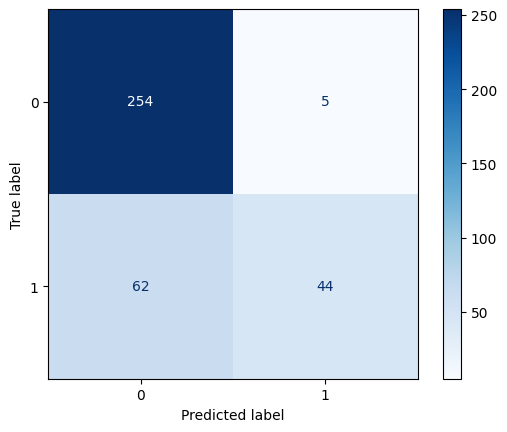

In [53]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues)
plt.show()

In [54]:
feature_mapping = {
    "PFSCR": "PD on Study (Central, RECIST) or Death",
    "LBTEST": "Lab Test ( different tests category )",
    "LSSLD": "Number of BL Metas Site",
    "LBSTRESN": "Numeric Result in Analysis Std Units for LBTEST",
}

In [55]:
for code, description in feature_mapping.items():
    print(f"{code}: {description}")

PFSCR: PD on Study (Central, RECIST) or Death
LBTEST: Lab Test ( different tests category )
LSSLD: Number of BL Metas Site
LBSTRESN: Numeric Result in Analysis Std Units for LBTEST


In [56]:
best_model = random_search.best_estimator_
xgb_classifier = best_model.named_steps['classifier']
importances = xgb_classifier.feature_importances_
feature_names = X_train.columns 
feature_importances = list(zip(feature_names, importances))
feature_importances_sorted = sorted(feature_importances, key=lambda x: x[1], reverse=True)


for feature, importance in feature_importances_sorted:
    print(f"Feature: {feature}, Importance: {importance}")


Feature: PFSCR, Importance: 0.32479971647262573
Feature: LBTEST_Carcinoembryonic Antigen, Importance: 0.2941512167453766
Feature: LBTEST_Lactate Dehydrogenase, Importance: 0.17486022412776947
Feature: LSSLD, Importance: 0.11694116145372391
Feature: LBSTRESN, Importance: 0.0892476737499237


In [57]:
import shap

explainer = shap.TreeExplainer(xgb_classifier)

shap_values = explainer.shap_values(X_train)

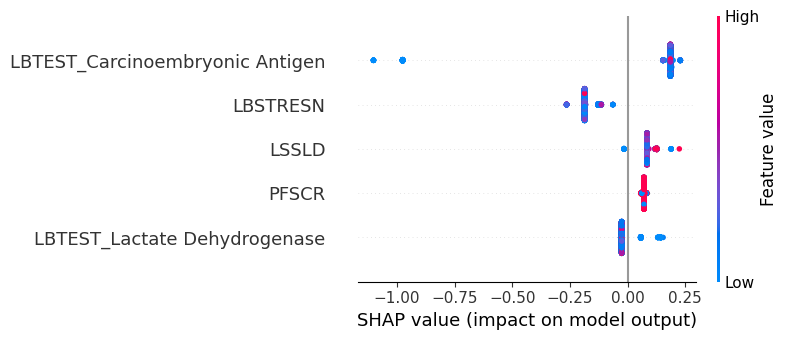

In [58]:
shap.summary_plot(shap_values, X_train)

In [59]:
shap_importance = np.abs(shap_values).mean(axis=0)
feature_importance = pd.DataFrame(list(zip(X_train.columns, shap_importance)), columns=['Feature', 'Importance'])

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print(feature_importance)


                           Feature  Importance
3  LBTEST_Carcinoembryonic Antigen    0.222010
1                         LBSTRESN    0.183106
2                            LSSLD    0.086202
0                            PFSCR    0.070915
4     LBTEST_Lactate Dehydrogenase    0.029293
